# 01 · Exploratory analysis

The six questions from `docs/PROJECT_DOCUMENTATION.md` §4, answered on the de-duplicated data.

**This notebook chooses nothing.** Models, features and thresholds are decided in `src/` on training data only;
this is where the data gets looked at, and where the figures in `reports/figures/` that describe the data come from.
It reads `data/raw/creditcard.csv` (run `python -m src.data --download` first).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from src.config import load_config, resolve
from src.data import RAW_FEATURES, deduplicate, load_raw
from src.features import V_COLS
from src.report import INK_2, MUTED, PAIR  # importing it applies the report's figure style
from src.splits import time_split

cfg = load_config()
FIGS = resolve(cfg["paths"]["reports"]) / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140, "display.max_columns", 14, "display.precision", 4)
LEGIT, FRAUD = PAIR  # legitimate blue, fraud orange in every figure


def show(fig, name):
    # save to reports/figures/ with the report's settings, then show it here
    fig.savefig(FIGS / name)
    plt.show()


raw = load_raw(resolve(cfg["data"]["raw_path"]))
df, dedup = deduplicate(raw)
print(f"{len(raw):,} rows in the file, {len(df):,} after removing exact duplicates")

284,807 rows in the file, 283,726 after removing exact duplicates


## 1. How rare is fraud?

In [2]:
counts = pd.DataFrame(
    {"rows": [len(raw), len(df)], "frauds": [int(raw.Class.sum()), int(df.Class.sum())]},
    index=["raw file", "after de-duplication"],
)
counts["fraud rate"] = counts.frauds / counts.rows
counts["legitimate per fraud"] = ((counts.rows - counts.frauds) / counts.frauds).round(1)
counts

,rows,frauds,fraud rate,legitimate per fraud
raw file,284807,492,0.0017,577.9
after de-duplication,283726,473,0.0017,598.8


## 2. What do the duplicate rows look like?

An exact duplicate matches another row in every column, `Time` and `Class` included. If one copy landed in the
training data and its twin in the test data, the model would be graded on a row it had memorised, so
`src/data.py` drops the extra copies before any split.

In [3]:
copies = raw[raw.duplicated(keep=False)]  # every row that has at least one exact twin
groups = copies.groupby(RAW_FEATURES + ["Class"]).size().rename("copies").reset_index()
print(f"{dedup['duplicates_dropped']:,} extra copies in {len(groups):,} groups of identical rows; "
      f"{dedup['fraud_duplicates_dropped']} of the extra copies are fraud")
print(f"rows with identical features but different labels: {dedup['same_features_different_label']}")
print("copies per group (all):  ", groups.copies.value_counts().sort_index().to_dict())

share_dup = pd.Series({
    "legitimate": raw[raw.Class == 0].duplicated().mean(),
    "fraud": raw[raw.Class == 1].duplicated().mean(),
}, name="share of rows that are an extra copy")
share_dup.to_frame()

1,081 extra copies in 773 groups of identical rows; 19 of the extra copies are fraud
rows with identical features but different labels: 0
copies per group (all):   {2: 611, 3: 66, 4: 81, 5: 10, 6: 1, 9: 2, 18: 2}


,share of rows that are an extra copy
legitimate,0.0037
fraud,0.0386


In [4]:
fraud_groups = groups[groups.Class == 1].assign(hour=lambda d: d.Time / 3600)
print(f"{len(fraud_groups)} groups of duplicated frauds, copies per group: "
      f"{fraud_groups.copies.value_counts().sort_index().to_dict()}")
print("median amount, duplicated frauds:", fraud_groups.Amount.median(),
      "| all frauds:", raw.loc[raw.Class == 1, "Amount"].median())
fraud_groups[["Time", "hour", "Amount", "copies"]].sort_values("Time").reset_index(drop=True)

13 groups of duplicated frauds, copies per group: {2: 11, 4: 1, 6: 1}
median amount, duplicated frauds: 44.9 | all frauds: 9.25


,Time,hour,Amount,copies
0,68207.0,18.9464,1.00,6
1,84204.0,23.3900,512.25,2
2,84204.0,23.3900,0.00,2
3,85285.0,23.6903,0.00,2
4,85285.0,23.6903,252.92,2
5,93853.0,26.0703,44.90,2
6,93853.0,26.0703,316.06,2
7,93860.0,26.0722,78.00,2
8,93860.0,26.0722,188.52,2
9,93879.0,26.0775,30.31,2


## 3. Do fraud amounts differ?

In [5]:
amounts = df.groupby("Class").Amount.describe(percentiles=[0.25, 0.5, 0.75, 0.95])
amounts["share = 0"] = df.groupby("Class").Amount.apply(lambda a: (a == 0).mean())
amounts["share <= 1"] = df.groupby("Class").Amount.apply(lambda a: (a <= 1).mean())
amounts.index = ["legitimate", "fraud"]
amounts

,count,mean,std,min,25%,50%,75%,95%,max,share = 0,share <= 1
legitimate,283253.0,88.4136,250.379,0.0,5.67,22.00,77.46,365.00,25691.16,0.0063,0.1065
fraud,473.0,123.8719,260.211,0.0,1.00,9.82,105.89,655.82,2125.87,0.0529,0.3615


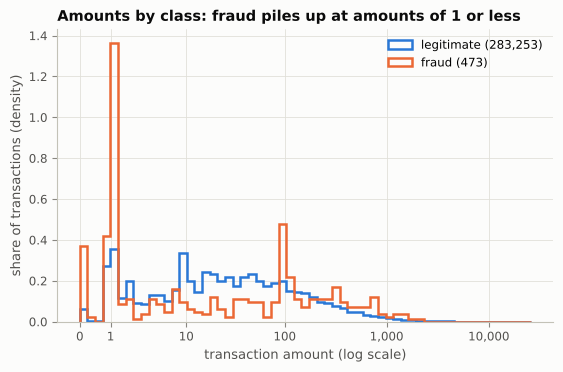

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
bins = np.linspace(0, np.log1p(df.Amount.max()), 60)
for cls, color, label in [(0, LEGIT, "legitimate"), (1, FRAUD, "fraud")]:
    ax.hist(np.log1p(df.loc[df.Class == cls, "Amount"]), bins=bins, density=True, histtype="step",
            lw=1.8, color=color, label=f"{label} ({(df.Class == cls).sum():,})")
ticks = [0, 1, 10, 100, 1_000, 10_000]
ax.set_xticks(np.log1p(ticks), [f"{t:,}" for t in ticks])
ax.set(xlabel="transaction amount (log scale)", ylabel="share of transactions (density)")
ax.set_title("Amounts by class: fraud piles up at amounts of 1 or less", fontsize=10.5)
ax.legend()
show(fig, "amount_by_class.png")

## 4. Is there a daily cycle in volume and in fraud rate?

`Time` counts seconds from the first transaction in the file, so the hour below is *hours since the file began*.
The shaded blocks are Protocol B's validation and test blocks (`src/splits.py`).

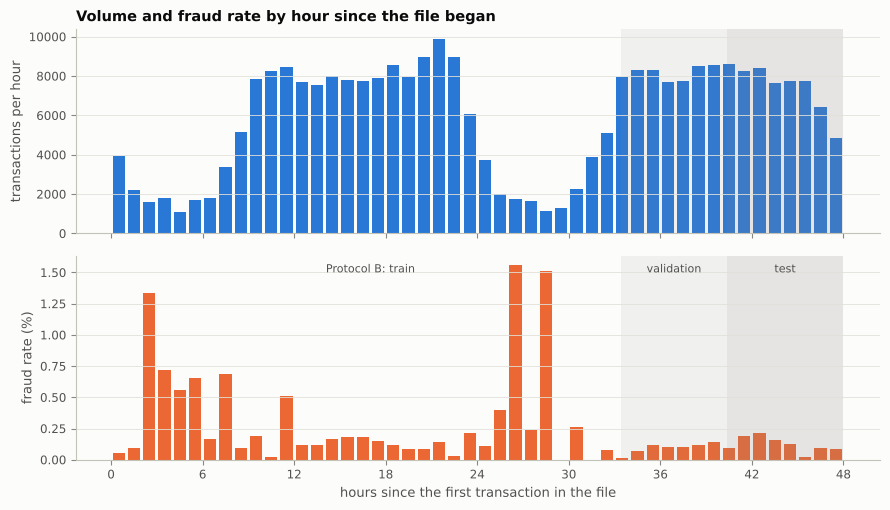

quietest hours since start: [2, 3, 4, 5, 26, 27, 28, 29]
Protocol B cut points (hours): [np.float64(33.44), np.float64(40.34)]


Time,0,1,2,3,4,5,6,...,41,42,43,44,45,46,47
transactions,3931.0000,2213.0000,1573.0000,1818.0000,1082.0000,1679.0000,1822.0000,...,8256.0000,8411.0000,7621.0000,7759.0000,7754.0000,6435.0000,4828.0000
frauds,2.0000,2.0000,21.0000,13.0000,6.0000,11.0000,3.0000,...,16.0000,18.0000,12.0000,10.0000,2.0000,6.0000,4.0000
fraud rate,0.0005,0.0009,0.0134,0.0072,0.0055,0.0066,0.0016,...,0.0019,0.0021,0.0016,0.0013,0.0003,0.0009,0.0008


In [7]:
hours = (df.Time // 3600).astype(int)  # 0..47
by_hour = df.groupby(hours).agg(transactions=("Class", "size"), frauds=("Class", "sum"))
by_hour["fraud rate"] = by_hour.frauds / by_hour.transactions

train, val, test = time_split(df, cfg["protocols"]["time"]["fractions"])
cuts = [val.Time.min() / 3600, test.Time.min() / 3600]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
top.bar(by_hour.index + 0.5, by_hour.transactions, width=0.8, color=LEGIT)
top.set(ylabel="transactions per hour")
top.set_title("Volume and fraud rate by hour since the file began", fontsize=10.5)
bottom.bar(by_hour.index + 0.5, 100 * by_hour["fraud rate"], width=0.8, color=FRAUD)
bottom.set(ylabel="fraud rate (%)", xlabel="hours since the first transaction in the file")
for ax in (top, bottom):
    ax.axvspan(cuts[0], cuts[1], color=MUTED, alpha=0.10, lw=0)
    ax.axvspan(cuts[1], 48, color=MUTED, alpha=0.20, lw=0)
    ax.grid(axis="x", visible=False)
for x, label in [(17, "Protocol B: train"), ((cuts[0] + cuts[1]) / 2, "validation"), ((cuts[1] + 48) / 2, "test")]:
    bottom.annotate(label, (x, 0.96), xycoords=("data", "axes fraction"), ha="center", va="top", color=INK_2, fontsize=8)
bottom.set_xticks(range(0, 49, 6))
fig.tight_layout()
show(fig, "volume_and_fraud_rate_by_hour.png")

quiet = by_hour.transactions.nsmallest(8).index.sort_values().tolist()
print("quietest hours since start:", quiet)
print("Protocol B cut points (hours):", [round(c, 2) for c in cuts])
by_hour.T

Protocol B's three blocks differ in more than time. Their fraud rates set each block's no-skill PR-AUC,
and their fraud amounts matter for the amount-based costs (E6) and for the cost ratio chosen in docs §2.2.

In [8]:
blocks = pd.DataFrame({
    name: {"rows": len(b), "frauds": int(b.Class.sum()), "fraud rate": b.Class.mean(),
           "mean fraud amount": b.loc[b.Class == 1, "Amount"].mean(),
           "median fraud amount": b.loc[b.Class == 1, "Amount"].median(),
           "first hour": b.Time.min() / 3600, "last hour": b.Time.max() / 3600}
    for name, b in [("train", train), ("validation", val), ("test", test)]
}).T
blocks

,rows,frauds,fraud rate,mean fraud amount,median fraud amount,first hour,last hour
train,170236.0,342.0,0.0020,112.9609,11.395,0.0000,33.4425
validation,56746.0,57.0,0.0010,214.5805,39.450,33.4428,40.3428
test,56744.0,74.0,0.0013,104.4280,4.795,40.3431,47.9978


## 5. Which components separate fraud from legitimate transactions?

Effect size: the difference in class means divided by the pooled standard deviation (Cohen's d), on the
de-duplicated data. The six largest get class-wise density plots.

In [9]:
X = df[V_COLS].assign(log_amount=np.log1p(df.Amount))
fraud, legit = X[df.Class == 1], X[df.Class == 0]
pooled = np.sqrt(((len(fraud) - 1) * fraud.var() + (len(legit) - 1) * legit.var()) / (len(X) - 2))
effect = ((fraud.mean() - legit.mean()) / pooled).rename("cohens_d").to_frame()
effect["abs_d"] = effect.cohens_d.abs()
effect = effect.sort_values("abs_d", ascending=False)
effect.head(10)

,cohens_d,abs_d
V17,-8.0924,8.0924
V14,-7.5222,7.5222
V12,-6.3482,6.3482
V10,-5.1856,5.1856
V16,-4.6709,4.6709
V3,-4.5453,4.5453
V7,-4.2887,4.2887
V11,3.6952,3.6952
V4,3.1969,3.1969
V18,-2.5965,2.5965


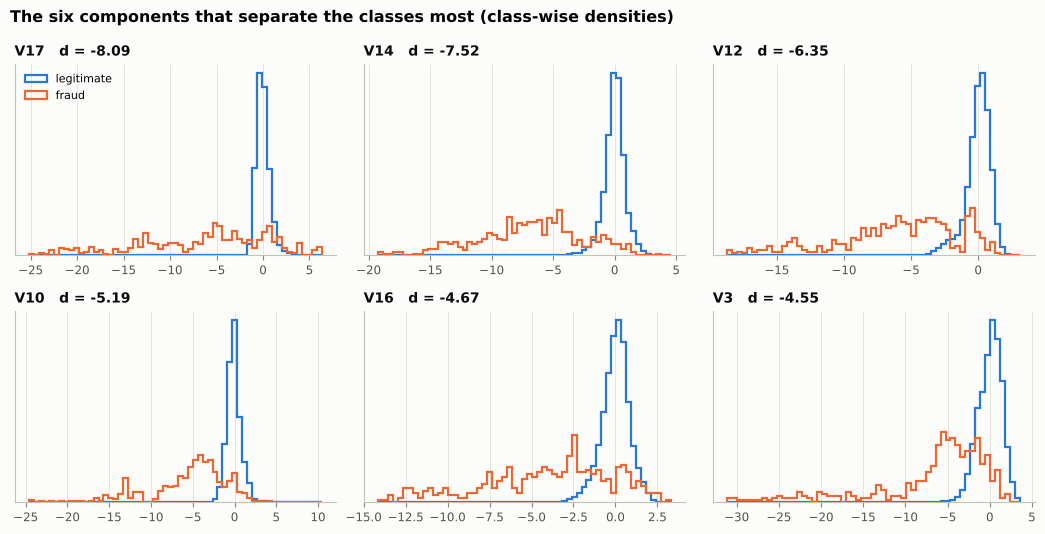

top six here: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']
often reported for this dataset: ['V14', 'V17', 'V12', 'V10'] -> all in our top six: True


In [10]:
top6 = effect.index[:6].tolist()
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.4))
for ax, col in zip(axes.flat, top6):
    lo, hi = np.percentile(X[col], [0.5, 99.95])
    bins = np.linspace(min(lo, fraud[col].min()), max(hi, fraud[col].quantile(0.99)), 60)
    ax.hist(legit[col].clip(bins[0], bins[-1]), bins=bins, density=True, histtype="step", lw=1.6, color=LEGIT, label="legitimate")
    ax.hist(fraud[col].clip(bins[0], bins[-1]), bins=bins, density=True, histtype="step", lw=1.6, color=FRAUD, label="fraud")
    ax.set_title(f"{col}   d = {effect.loc[col, 'cohens_d']:+.2f}", fontsize=10)
    ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("The six components that separate the classes most (class-wise densities)", x=0.01, ha="left",
             fontsize=11.5, fontweight="bold")
fig.tight_layout()
show(fig, "top_components_by_class.png")
common = ["V14", "V17", "V12", "V10"]
print("top six here:", top6)
print("often reported for this dataset:", common, "-> all in our top six:", set(common) <= set(top6))

## 6. Are V1–V28 uncorrelated with each other?

largest |correlation| between two components: 0.019 (V8 vs V21)
Amount vs components, largest: {'V2': -0.533, 'V7': 0.4, 'V5': -0.388, 'V20': 0.341}
Time vs components, largest:   {'V3': -0.422, 'V11': -0.249, 'V25': -0.233, 'V15': -0.184}


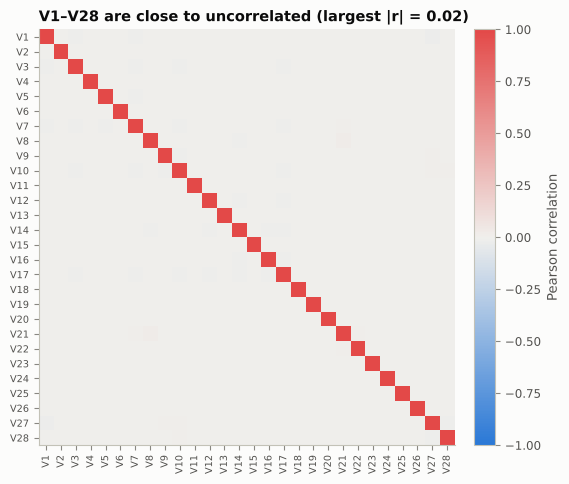

In [11]:
corr = df[V_COLS].corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
pair = off_diag.stack().idxmax()
print(f"largest |correlation| between two components: {off_diag.max().max():.3f} ({pair[0]} vs {pair[1]})")

amount_corr = df[V_COLS].corrwith(df.Amount).sort_values(key=abs, ascending=False)
time_corr = df[V_COLS].corrwith(df.Time).sort_values(key=abs, ascending=False)
print("Amount vs components, largest:", amount_corr.head(4).round(3).to_dict())
print("Time vs components, largest:  ", time_corr.head(4).round(3).to_dict())

diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(28), V_COLS, rotation=90, fontsize=7)
ax.set_yticks(range(28), V_COLS, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
ax.set_title(f"V1–V28 are close to uncorrelated (largest |r| = {off_diag.max().max():.2f})", fontsize=10.5)
show(fig, "correlation_heatmap.png")

## Findings

1. **Rarity.** 492 of 284,807 transactions are fraud (0.173%). After removing exact duplicates, 473 of 283,726 (0.167%): about one fraud per 600 legitimate transactions.
2. **Duplicates.** 1,081 extra copies in 773 groups of identical rows, with no conflicting labels. Fraud rows are ten times as likely to be an extra copy (3.9% against 0.37%). The 19 duplicated fraud copies come from 13 groups that cluster in time: six groups fall within 26 seconds of each other around hour 26, and two are transactions of 1.00 repeated four and six times, a pattern consistent with repeated attempts. Their median amount is 44.90, against 9.25 for all frauds in the raw file.
3. **Amounts.** Fraud piles up at tiny amounts: 36% of frauds are 1.00 or less, against 11% of legitimate transactions, and 5.3% are exactly 0 (0.6% of legitimate). Fraud also has a heavier upper tail (95th percentile 656 against 365), although the largest amounts in the file are legitimate (25,691 against 2,126 for fraud).
4. **Daily cycle.** Volume is lowest 2–5 and 26–29 hours after the file starts, so the file probably starts near midnight; the dataset doesn't say. The fraud rate is highest in those quiet hours (above 1.3% in hours 2, 26 and 28, against roughly 0.1–0.2% in the daytime). Protocol B's validation block covers hours 33.4–40.3 and its test block hours 40.3–48.0, the daytime and evening of the second day, with lower fraud rates (0.10% and 0.13%) than the training block (0.20%), which holds both nights. Fraud amounts differ by block too: mean 113 in training, 215 in validation and 104 in test.
5. **Separating components.** The largest effect sizes are V17, V14, V12, V10, V16 and V3 (|d| from 8.1 down to 4.5). The four most often reported for this dataset, V14, V17, V12 and V10, are all in the top six.
6. **Correlation.** V1–V28 are essentially uncorrelated with one another (largest |r| = 0.019, V8 against V21), as expected if the PCA was fitted on these rows. `Amount` and `Time` are not: `Amount` correlates with V2 (−0.53), V7 (0.40) and V5 (−0.39), and `Time` with V3 (−0.42). So some time information survives in the components even though raw `Time` is dropped (docs §5).
